# 指数估值榜 + 通道拨测（wmshare notebook）

只用 [wmshare](https://github.com/open-winmale/wmshare) 一个数据源：

- **榜单**：`index.universe_keys()`（已注册成分宇宙的宽基键）× `index.valuation(key)`
  （整体法 PE/PB/股息率当前值）× `index.trend(key)`（周频整体法序列 → PE/PB 历史分位）
  × 盈利收益率 vs 10 年期国债 → 三档参考区间 + 市场温度星级
- **拨测**：`probe(symbol)` 按需能力——任意场内 ETF/指数键的价格通道（μ±2σ、z 值、
  近 3 年分位、可选 μ∓1σ 单轮回看）

> 档位口径：盈利收益率 = 1/PE；> 2×10Y 国债记绿档、1~2× 记黄档、< 1× 记橙档——
> 行业通行规则的**估值参考区间，非官方阈值**；全文只做数据整理与研究参考，
> **不构成任何投资建议**。整体法口径与主流终端（Wind 等）实测差 <1%（2026-11-07）。

In [1]:
import math
import os
from collections import Counter
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt

plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["font.sans-serif"] = ["Hiragino Sans GB", "PingFang SC",
                                   "Arial Unicode MS", "SimHei", "sans-serif"]

from wmshare import Client, demo_client


def load_credentials() -> None:
    """凭证从 ~/.wmshare/credentials.env 读（也可直接 export WMSHARE_CLIENT_ID/SECRET）。"""
    for p in (Path.home() / ".wmshare/credentials.env",
              Path.home() / ".winmale/credentials.env"):
        if not p.exists():
            continue
        for line in p.read_text(encoding="utf-8").splitlines():
            line = line.strip()
            if line and not line.startswith("#") and "=" in line:
                k, v = line.split("=", 1)
                os.environ.setdefault(k.strip(), v.strip().strip('"').strip("'"))


DEMO = False  # True = 离线演示数据（零凭证零请求）
if DEMO:
    cli = demo_client()
else:
    load_credentials()
    # 3 年日频 760 根 > 默认单次上限 500，拨测场景放宽
    cli = Client.from_env(max_limit=800)
print("client ready:", "demo" if DEMO else "live")

client ready: live


## 一、指数估值榜

每键一次 `valuation`（当前值）+ 一次 `trend`（周频序列分位）。`trend` 依赖平台预热缓存
（cron 每收盘刷新），未命中的键分位列显示「缓存未命中」，其余列不受影响。

In [2]:
# universe_keys 需服务端部署 indices.trend/universe_keys 后返回真实清单；
# 未生效时用探针实证键清单兜底（2026-11-07，11 键全部 valuation 可用）
FALLBACK_KEYS = ["index.hs300", "index.csi500", "index.sz50", "index.cybz", "index.star50",
                 "index.shzs", "index.szcz", "index.zx100", "index.szzzs", "index.gz2000",
                 "index.kc200"]
try:
    keys = cli.index.universe_keys() or FALLBACK_KEYS
except Exception:
    keys = FALLBACK_KEYS
rf = None
try:  # 无风险利率锚：10 年期国债收益率（小数口径）
    rf = cli.indicator.get("600519", "$BOND_YIELD_GOV_10Y")
    rf = round(rf * 100, 2) if isinstance(rf, (int, float)) else None
except Exception as e:
    print("[rf] 不可用：", e)
print(f"universe keys={len(keys)}  10Y 国债={rf}%")


def zone_of(ey: float | None, rf: float | None) -> str:
    """盈利收益率法三档（估值参考区间，非官方阈值）。"""
    if not ey or not rf:
        return "—"
    if ey > 2 * rf:
        return "绿档"
    if ey >= rf:
        return "黄档"
    return "橙档"


rows = []
for k in keys:
    try:
        v = cli.index.valuation(k)
    except Exception as e:
        rows.append({"指数": k, "PE": None, "备注": f"valuation 不可用：{e}"[:40]})
        continue
    cur = v.get("current") or {}
    pe, pb, dv = cur.get("pe"), cur.get("pb"), cur.get("dv")
    name_cn = ""
    try:  # 季序列点带日期，取序列键名展示用中文（若无则用键名）
        name_cn = k.replace("index.", "").upper()
    except Exception:
        pass
    row = {"指数": name_cn or k, "key": k,
           "PE": round(pe, 2) if isinstance(pe, (int, float)) else None,
           "PB": round(pb, 2) if isinstance(pb, (int, float)) else None,
           "股息率": round(dv * 100, 2) if isinstance(dv, (int, float)) else None,
           "盈利收益率": round(100 / pe, 2) if isinstance(pe, (int, float)) and pe > 0 else None}
    try:
        t = cli.index.trend(k)
        pts = t.get("points") or []
        row["PE分位"] = (round(t["pe_pct"] * 100, 1) if t.get("pe_pct") is not None else None)
        row["PB分位"] = (round(t["pb_pct"] * 100, 1) if t.get("pb_pct") is not None else None)
        row["趋势n"] = t.get("n") or len(pts)
        row["趋势asof"] = t.get("as_of") or ""
    except Exception as e:
        row["PE分位"] = row["PB分位"] = None
        row["趋势n"] = 0
        row["趋势asof"] = f"trend 不可用：{e}"[:40]
    row["档位"] = zone_of(row["盈利收益率"], rf)
    rows.append(row)

CN = {"HS300": "沪深300", "CSI500": "中证500", "SZ50": "上证50", "CYBZ": "创业板指",
      "STAR50": "科创50", "SHZS": "上证指数", "SZCZ": "深证成指", "ZX100": "中小100",
      "SZZZS": "深证300", "GZ2000": "国证2000", "KC200": "科创200"}
for r in rows:
    r["指数"] = CN.get(r.get("key", "").replace("index.", "").upper(), r["指数"])

ordered = sorted(rows, key=lambda r: (r.get("档位") != "绿档", r.get("档位") != "黄档",
                                      -(r.get("盈利收益率") or 0)))
rated = [r for r in ordered if r.get("档位") in ("绿档", "黄档", "橙档")]
green_n = sum(1 for r in rated if r["档位"] == "绿档")
share = green_n / len(rated) if rated else 0
stars = (5 if share >= 0.8 else 4 if share >= 0.6 else 3 if share >= 0.4
         else 2 if share >= 0.2 else 1 if green_n else 0)

hdr = f"指数估值榜 · 市场温度 {'★' * stars}{'☆' * (5 - stars)}　绿档 {green_n}/{len(rated)}"
print(hdr)
cols = ["指数", "PE", "PE分位", "PB", "PB分位", "股息率", "盈利收益率", "档位", "趋势asof"]
try:
    import pandas as pd
    from IPython.display import display
    df = pd.DataFrame([{c: r.get(c) for c in cols} for r in ordered])
    def _hl(s):
        return [f"color:{' #1a7f37' if v == '绿档' else '#9a6700' if v == '黄档' else '#bc4c00' if v == '橙档' else 'inherit'};font-weight:bold"
                if c == "档位" else "" for c, v in zip(s.index, s)]
    display(df.style.apply(_hl).hide(axis="index"))
except ImportError:
    for r in ordered:
        print("  ".join(f"{r.get(c)}" for c in cols))
print("档位=盈利收益率法参考区间（非官方阈值）；分位=周频整体法序列；不构成投资建议。")

universe keys=11  10Y 国债=1.68%


指数估值榜 · 市场温度 ★★★★☆　绿档 7/11


指数,PE,PE分位,PB,PB分位,股息率,盈利收益率,档位,趋势asof
上证50,11.670000,44.400000,1.130000,38.900000,2.650000,8.570000,绿档,2026-11-06
沪深300,13.380000,30.500000,1.240000,24.300000,2.300000,7.470000,绿档,2026-11-06
上证指数,15.900000,nan,1.310000,nan,1.970000,6.290000,绿档,
中小100,21.510000,nan,2.450000,nan,1.510000,4.650000,绿档,
深证成指,24.440000,nan,2.280000,nan,1.810000,4.090000,绿档,
创业板指,28.110000,48.100000,4.100000,57.800000,1.270000,3.560000,绿档,2026-11-06
中证500,28.150000,24.300000,2.030000,36.400000,1.540000,3.550000,绿档,2026-11-06
深证300,34.140000,nan,2.280000,nan,1.490000,2.930000,黄档,
国证2000,47.300000,nan,2.160000,nan,1.170000,2.110000,黄档,
科创50,92.730000,22.400000,6.120000,4.100000,0.250000,1.080000,橙档,2026-11-06


档位=盈利收益率法参考区间（非官方阈值）；分位=周频整体法序列；不构成投资建议。


## 二、通道拨测（按需能力）

`probe(symbol)` 对任意场内 ETF/指数键出价格通道：前复权日 K → 份额折算跳变清理 →
μ±2σ 通道、z 值、近 3 年分位；`backtest=True` 附 μ∓1σ 单轮机械回看（限价成交、T+1、
收盘口径；**算法演示，非预测**）。

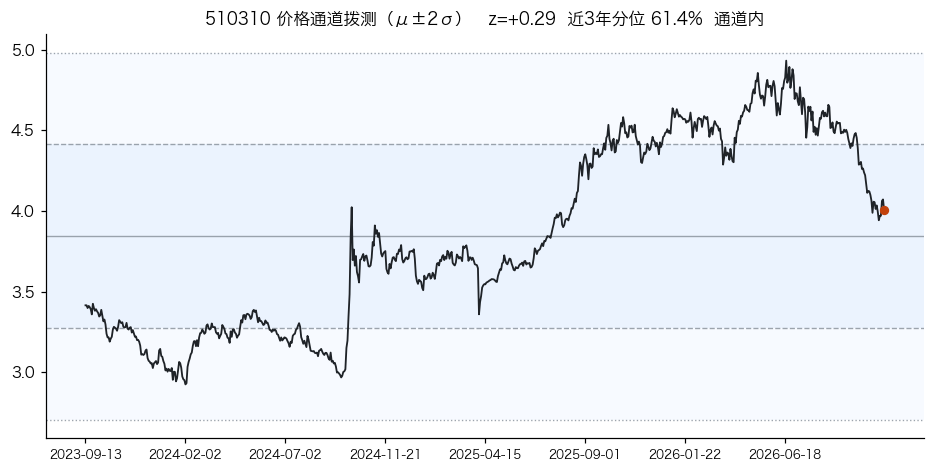

[极值·日线·前复权口径] 窗口最高 4.940 @2026-06-23  最低 2.846 @2024-02-02
[回看·算法演示非预测] μ∓1σ 单轮：收益 +34.81%  持仓 474 日  最大回撤 16.51%  已出场


In [3]:
def clean_series(closes, dates, jump=0.25):
    """qfq 不处理份额折算：单日 |涨跌|>jump 的断点之后才是统计纯净子窗口。"""
    for i in range(1, len(closes)):
        prev = closes[i - 1]
        if prev and abs(closes[i] / prev - 1) > jump:
            return closes[i:], dates[i:], f"自{dates[i]}（剔除份额折算跳变）"
    return closes, dates, ""


def channel(closes: list[float]) -> dict:
    """均值 ± 1σ/2σ 通道 + z 值 + 分位（σ=总体标准差 ÷N）。"""
    n = len(closes)
    mu = sum(closes) / n
    sd = math.sqrt(sum((c - mu) ** 2 for c in closes) / n) or 1e-9
    last = closes[-1]
    z = (last - mu) / sd
    pct = sum(1 for c in closes if c <= last) / n
    if z > 2:
        zone = "上轨上方"
    elif z > 1:
        zone = "上轨附近"
    elif z >= -1:
        zone = "通道内"
    elif z >= -2:
        zone = "下轨附近"
    else:
        zone = "下轨下方"
    return {"mu": mu, "sd": sd, "lower1": mu - sd, "upper1": mu + sd,
            "lower2": max(0.0, mu - 2 * sd), "upper2": mu + 2 * sd,
            "z": z, "pct": pct, "zone": zone, "n": n}


def backtest_band(bars: list[dict], buy: float, sell: float) -> dict:
    """μ∓1σ 单轮回看：限价成交（跳空按更优价）、T+1 当日不卖、收盘口径持仓。"""
    n = len(bars)
    i = 0
    while i < n and not (bars[i]["low"] <= buy):
        i += 1
    if i >= n:
        return {"traded": False, "distance_to_buy": buy / bars[-1]["close"] - 1}
    fill = min(bars[i]["open"], buy)
    holding = [bars[i]["close"]]
    j = i + 1
    sell_fill = None
    while j < n:
        holding.append(bars[j]["close"])
        if bars[j]["high"] >= sell:
            sell_fill = max(bars[j]["open"], sell)
            break
        j += 1
    mdd, peak = 0.0, fill
    for c in holding:
        peak = max(peak, c)
        mdd = max(mdd, 1 - c / peak)
    if sell_fill is None:
        return {"traded": True, "ret": holding[-1] / fill - 1, "days": len(holding),
                "mdd": mdd, "still_holding": True}
    return {"traded": True, "ret": sell_fill / fill - 1, "days": len(holding),
            "mdd": mdd, "still_holding": False}


def probe(symbol: str, n: int = 760, backtest: bool = True, plot: bool = True) -> dict:
    """按需拨测：symbol = 场内 ETF 代码（如 510310）或指数键（如 index.hs300）。

    极值与回看全部基于**日线 OHLC**：窗口最高/最低取日 K 的 high/low（含日期），
    回看买卖触发用日内 low/high（限价成交语义），通道统计仍用收盘序列。
    """
    bars_raw = cli.kline.bars(symbol, n=n, adj="qfq")
    rows = bars_raw.get("bars", bars_raw) if isinstance(bars_raw, dict) else bars_raw
    rows = sorted(rows or [], key=lambda r: str(r.get("date") or r.get("samplingTs") or ""))
    bars = [{"date": str(r.get("date") or "")[:10],
             "open": float(r["open"]), "high": float(r["high"]),
             "low": float(r["low"]), "close": float(r["close"])}
            for r in rows if r.get("close")]
    # 折算跳变清理：整行截断（保持 OHLC 对齐），qfq 已消除大部分折算，>25% 残留再兜底
    note = ""
    for i in range(1, len(bars)):
        prev = bars[i - 1]["close"]
        if prev and abs(bars[i]["close"] / prev - 1) > 0.25:
            bars, note = bars[i:], f"自{bars[i]['date']}（剔除份额折算跳变）"
            break
    closes = [b["close"] for b in bars]
    dates = [b["date"] for b in bars]
    ch = channel(closes)
    out = {"symbol": symbol, "n": ch["n"], "note": note, **ch}
    # 日线极值（high/low 口径，含日期）
    hi = max(bars, key=lambda b: b["high"])
    lo = min(bars, key=lambda b: b["low"])
    out["window_high"] = {"price": hi["high"], "date": hi["date"]}
    out["window_low"] = {"price": lo["low"], "date": lo["date"]}
    if backtest and ch["n"] >= 120:
        bt = backtest_band(bars, ch["lower1"], ch["upper1"])
        out["backtest"] = bt
    if plot:
        fig, ax = plt.subplots(figsize=(8.6, 4.4), dpi=110)
        ax.axhspan(ch["lower1"], ch["upper1"], facecolor="#dbeafe", alpha=0.55, zorder=0)
        ax.axhspan(ch["lower2"], ch["lower1"], facecolor="#eff6ff", alpha=0.45, zorder=0)
        ax.axhspan(ch["upper1"], ch["upper2"], facecolor="#eff6ff", alpha=0.45, zorder=0)
        for v, lab, ls in ((ch["lower2"], "-2σ", ":"), (ch["lower1"], "-1σ", "--"),
                           (ch["mu"], "μ", "-"), (ch["upper1"], "+1σ", "--"),
                           (ch["upper2"], "+2σ", ":")):
            ax.axhline(v, color="#8b949e", lw=0.9, ls=ls, alpha=0.85, zorder=1)
        x = list(range(len(closes)))
        ax.plot(x, closes, color="#1f2328", lw=1.2, zorder=2)
        ax.scatter([x[-1]], [closes[-1]], color="#c2410c", s=26, zorder=3)
        ax.set_title(f"{symbol} 价格通道拨测（μ±2σ{('·' + note) if note else ''}）　"
                     f"z={ch['z']:+.2f}  近3年分位 {ch['pct'] * 100:.1f}%  {ch['zone']}",
                     fontsize=11)
        step = max(1, len(x) // 8)
        ax.set_xticks(x[::step])
        ax.set_xticklabels(dates[::step], fontsize=8)
        for sp in ("top", "right"):
            ax.spines[sp].set_visible(False)
        plt.tight_layout()
        plt.show()
    print(f"[极值·日线·前复权口径] 窗口最高 {out['window_high']['price']:.3f} @{out['window_high']['date']}  "
          f"最低 {out['window_low']['price']:.3f} @{out['window_low']['date']}")
    bt = out.get("backtest")
    if bt and bt.get("traded"):
        sign = "+" if bt["ret"] >= 0 else ""
        tail = "仍在持仓" if bt.get("still_holding") else "已出场"
        print(f"[回看·算法演示非预测] μ∓1σ 单轮：收益 {sign}{bt['ret'] * 100:.2f}%  "
              f"持仓 {bt['days']} 日  最大回撤 {bt['mdd'] * 100:.2f}%  {tail}")
    elif bt:
        print(f"[回看] 从未触发买轨，距买轨 {bt['distance_to_buy'] * 100:+.1f}%")
    return out


# 按需调用示例（改成任何你关注的标的）：
_ = probe("510310", backtest=True)   # 沪深300ETF


## 三、口径与免责

- 估值=整体法（Σ市值/Σ盈利），平台指数域预热计算，与主流终端实测差 <1%（2026-11-07）；
- 分位=最新值在周频整体法序列中的位置（0=最低，1=最高），样本 <60 点不给出；
- 档位=盈利收益率法三档参考区间，行业通行规则，**非官方阈值**；
- 回看为日线 OHLC 限价单模拟（触发用日内 low/high），**算法演示，非预测**；
- 全部内容为数据整理与研究参考，**不构成任何投资建议**。